# WP1 — How Much Does Data Leakage Inflate Brain Tumor MRI Accuracy?

**Author:** Md. Selim Mia — Department of Artificial Intelligence, Nanjing University of Information Science & Technology

**Thesis work package 1.** The same model and the same training recipe are trained and tested under three split protocols.
The only thing that changes is how the images are divided, so any accuracy difference is caused by the split.

| Protocol | Data | How train / val / test are formed | Leakage |
|---|---|---|---|
| **A. Official split** | 7,200 images as distributed (duplicates kept) | the dataset's own Training / Testing folders; val = random 15 % of Training | near duplicates cross into test (v2 audit: 36.25 %) |
| **B. Random image-level split** | de-duplicated pool (same images as C) | stratified random split by image, same sizes as C | near duplicates can cross into test |
| **C. Group-aware split (ours)** | de-duplicated pool | StratifiedGroupKFold on duplicate groups (identical to v2) | none, verified |

**Two models per protocol**
1. **Fusion CNN** (EfficientNetV2-B0 + ResNet50V2), the v2 recipe: 288 px, two-phase training, warm-up + cosine, label smoothing, TTA.
2. **1-nearest-neighbour memoriser**: copies the label of the most similar training image (normalised cross-correlation on 64×64 pixels).
   It learns nothing about tumours, so a high score from it means the test set can be answered by memory.

**Outputs:** `wp1_outputs.zip` (results_wp1.json, tables, figures). Accuracy on test images that have a duplicate in training is
reported separately from accuracy on genuinely unseen images.

**Runtime:** GPU T4, Internet ON, about 2–2.5 h. Use *Save Version → Save & Run All (Commit)*.

In [3]:
# ============================================================
# CELL 1 — Configuration and imports
# ============================================================
import os, sys, gc, json, time, random, hashlib, shutil, warnings, platform

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["PYTHONHASHSEED"] = "42"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy.fft import dct
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, cohen_kappa_score, matthews_corrcoef, roc_auc_score, log_loss,
)

import tensorflow as tf
import keras
from keras import layers

CFG = {
    # ---- paths ----
    "DATA_ROOT": os.environ.get(
        "DATA_ROOT", "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"),
    "WORK_DIR": os.environ.get("WORK_DIR", "/kaggle/working"),
    # ---- reproducibility ----
    "SEED": 42,
    # ---- images ----
    "IMG_SIZE": 288,
    "FINGERPRINT_SIZE": 224,  # same as v1/v2 -> identical duplicate groups and identical Protocol C split
    "BATCH_SIZE": 32,
    # ---- de-duplication ----
    "PHASH_MAX_DIST": 8,
    "NCC_MIN": 0.90,
    # ---- splits ----
    "TEST_FOLDS": 7,
    "VAL_FOLDS": 6,
    "OFFICIAL_VAL_FRACTION": 0.15,
    # ---- model: the v2 fusion model (change to ("resnet50v2",) for a ~2x faster run) ----
    "BACKBONES": ("effnetv2b0", "resnet50v2"),
    # ---- training (identical to v2) ----
    "HEAD_EPOCHS": 12,
    "HEAD_LR": 1e-3,
    "FT_EPOCHS": 35,
    "FT_LR": 5e-5,
    "WARMUP_EPOCHS": 1,
    "LABEL_SMOOTHING": 0.1,
    "HEAD_PATIENCE": 4,
    "FT_PATIENCE": 8,
    # ---- inference ----
    "TTA": True,
    "BOOTSTRAP_ROUNDS": 1000,
    # ---- misc ----
    "MIXED_PRECISION": True,
    "N_JOBS": -1,
    "SMOKE_TEST": os.environ.get("SMOKE_TEST", "0") == "1",
}
if CFG["SMOKE_TEST"]:
    CFG.update(IMG_SIZE=96, BATCH_SIZE=8, HEAD_EPOCHS=1, FT_EPOCHS=1, BOOTSTRAP_ROUNDS=50)

SEED, IMG, FP = CFG["SEED"], CFG["IMG_SIZE"], CFG["FINGERPRINT_SIZE"]
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
CLASS_TITLES = {"glioma": "Glioma", "meningioma": "Meningioma",
                "notumor": "No tumor", "pituitary": "Pituitary"}
CLASS_MAP = {
    "glioma": "glioma", "glioma_tumor": "glioma",
    "meningioma": "meningioma", "meningioma_tumor": "meningioma",
    "notumor": "notumor", "no_tumor": "notumor", "no": "notumor",
    "pituitary": "pituitary", "pituitary_tumor": "pituitary",
}
CIDX = {c: i for i, c in enumerate(CLASSES)}
PROTOCOLS = {
    "A": "A. Official split",
    "B": "B. Random image-level split",
    "C": "C. Group-aware split (ours)",
}

OUT_DIR = os.path.join(CFG["WORK_DIR"], "wp1_outputs")
FIG_DIR = os.path.join(OUT_DIR, "figures")
TAB_DIR = os.path.join(OUT_DIR, "tables")
PROC_DIR = os.path.join(CFG["WORK_DIR"], "processed_images")
MODEL_DIR = os.path.join(CFG["WORK_DIR"], "models_wp1")
for d in (OUT_DIR, FIG_DIR, TAB_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)
if os.path.exists(PROC_DIR):
    shutil.rmtree(PROC_DIR)
os.makedirs(PROC_DIR)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    keras.utils.set_random_seed(seed)


set_seed()

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception:
        pass

GPU_NAME, CC = "CPU", (0, 0)
if gpus:
    try:
        det = tf.config.experimental.get_device_details(gpus[0])
        GPU_NAME, CC = det.get("device_name", "GPU"), det.get("compute_capability", (0, 0))
    except Exception:
        GPU_NAME = "GPU"
USE_MP = CFG["MIXED_PRECISION"] and gpus and CC[0] >= 7
if USE_MP:
    keras.mixed_precision.set_global_policy("mixed_float16")

ENV_INFO = {"python": platform.python_version(), "tensorflow": tf.__version__,
            "keras": keras.__version__, "numpy": np.__version__, "opencv": cv2.__version__,
            "device": GPU_NAME, "mixed_precision": bool(USE_MP)}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.family": "serif",
                     "font.size": 11, "axes.titleweight": "bold"})


def save_fig(name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.savefig(path, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    print(f"   saved -> {path}")


RESULTS = {"config": CFG, "environment": ENV_INFO}


def save_results():
    with open(os.path.join(OUT_DIR, "results_wp1.json"), "w") as fj:
        json.dump(RESULTS, fj, indent=2, default=str)


print("Environment:", json.dumps(ENV_INFO, indent=2))

Environment: {
  "python": "3.13.16",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "numpy": "2.1.3",
  "opencv": "4.14.0",
  "device": "Tesla T4",
  "mixed_precision": true
}


In [4]:
# ============================================================
# CELL 2 — Locate the dataset and list every image
# ============================================================
VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")


def find_root(preferred):
    if os.path.isdir(preferred):
        return preferred
    for r, d, _ in os.walk("/kaggle/input"):
        if any(x.lower() == "training" for x in d):
            return r
    raise FileNotFoundError(f"Dataset not found at {preferred}")


DATA_ROOT = find_root(CFG["DATA_ROOT"])
records = []
for r, _, files in os.walk(DATA_ROOT):
    cls = CLASS_MAP.get(os.path.basename(r).lower())
    if cls is None:
        continue
    official = "test" if "test" in r.lower() else "train"
    for f in sorted(files):
        if f.lower().endswith(VALID_EXT):
            records.append({"src_path": os.path.join(r, f), "label": cls, "official_split": official})

df = pd.DataFrame(records).sort_values("src_path").reset_index(drop=True)
if CFG["SMOKE_TEST"]:
    df = (df.sample(frac=1.0, random_state=SEED).groupby("label").head(60)
            .sort_values("src_path").reset_index(drop=True))

print(f"Dataset root : {DATA_ROOT}\nTotal images : {len(df)}\n")
raw_counts = pd.crosstab(df["label"], df["official_split"], margins=True, margins_name="Total")
print(raw_counts)
raw_counts.to_csv(os.path.join(TAB_DIR, "table_raw_dataset_counts.csv"))

Dataset root : /kaggle/input/datasets/mdselimmia/masoud-nickparvar
Total images : 7200

official_split  test  train  Total
label                             
glioma           400   1400   1800
meningioma       400   1400   1800
notumor          400   1400   1800
pituitary        400   1400   1800
Total           1600   5600   7200


In [5]:
# ============================================================
# CELL 3 — Preprocessing (parallel): brain cropping, resizing, fingerprints
# ============================================================
def crop_brain(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, th = cv2.threshold(blur, 45, 255, cv2.THRESH_BINARY)
    th = cv2.erode(th, None, iterations=2)
    th = cv2.dilate(th, None, iterations=2)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return img
    x, y, w, h = cv2.boundingRect(max(cnts, key=cv2.contourArea))
    if w < 0.2 * img.shape[1] or h < 0.2 * img.shape[0]:
        return img
    return img[y:y + h, x:x + w]


def phash64(gray):
    g = cv2.resize(gray, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
    d = dct(dct(g, axis=0, norm="ortho"), axis=1, norm="ortho")[:8, :8]
    return np.packbits((d > np.median(d)).flatten()).view(">u8")[0]


def ncc_vector(gray):
    v = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
    v -= v.mean()
    return v / (np.linalg.norm(v) + 1e-8)


def process(i, src, label):
    raw = open(src, "rb").read()
    img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        return None
    crop = crop_brain(img)
    gray_fp = cv2.cvtColor(cv2.resize(crop, (FP, FP), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    out = os.path.join(PROC_DIR, f"{i:05d}_{label}.png")
    cv2.imwrite(out, cv2.resize(crop, (IMG, IMG), interpolation=cv2.INTER_AREA))
    return hashlib.md5(raw).hexdigest(), phash64(gray_fp), ncc_vector(gray_fp), out


t0 = time.time()
cv2.setNumThreads(1)
outs = Parallel(n_jobs=CFG["N_JOBS"], batch_size=32)(
    delayed(process)(i, r.src_path, r.label) for i, r in enumerate(df.itertuples()))
ok = [o is not None for o in outs]
n_unreadable = int(len(ok) - sum(ok))
df = df[ok].reset_index(drop=True)
outs = [o for o in outs if o is not None]
df["md5"] = [o[0] for o in outs]
df["phash"] = [o[1] for o in outs]
df["path"] = [o[3] for o in outs]
df["ridx"] = np.arange(len(df))     # row index into the NCC matrix
NCC = np.stack([o[2] for o in outs])
print(f"Preprocessed {len(df)} images in {time.time() - t0:.1f}s (unreadable: {n_unreadable})")

Preprocessed 7200 images in 83.4s (unreadable: 0)


De-duplication report: {
  "images_found": 7200,
  "unreadable_removed": 0,
  "exact_duplicate_links": 187,
  "near_duplicate_links": 3391,
  "exact_duplicates_removed": 186,
  "conflicting_label_images_removed": 11,
  "final_images": 7003,
  "final_groups": 5364,
  "largest_group": 18,
  "official_test_images": 1600,
  "official_test_with_exact_copy_in_train": 0,
  "official_test_with_exact_or_near_duplicate_in_train": 580,
  "percent_official_test_leaked": 36.25
}


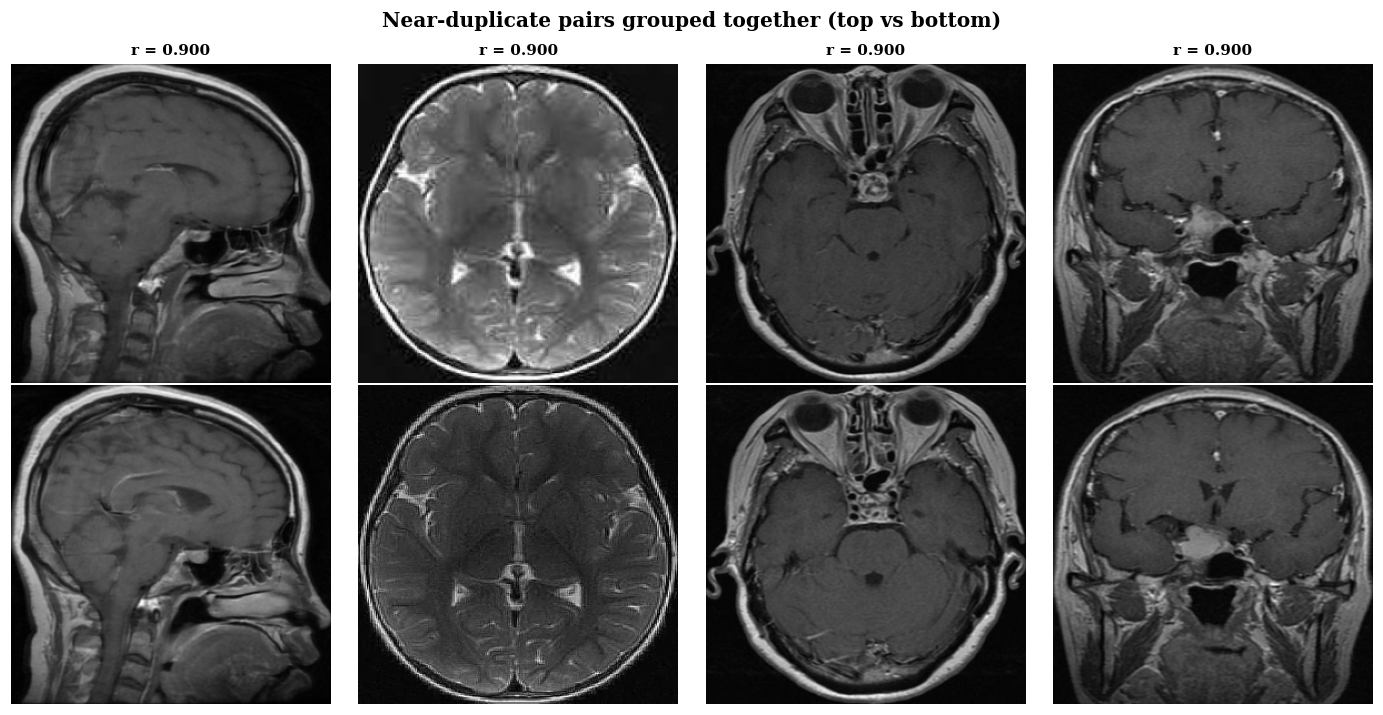

   saved -> /kaggle/working/wp1_outputs/figures/fig_near_duplicate_examples.png


In [6]:
# ============================================================
# CELL 4 — Exact + near-duplicate grouping and leakage audit
# ============================================================
N = len(df)
H = df["phash"].to_numpy(dtype=np.uint64)
POP = np.array([bin(i).count("1") for i in range(256)], np.uint8)
parent = np.arange(N)


def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a


def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb)


exact_pairs = 0
for _, idx in df.groupby("md5").indices.items():
    for j in idx[1:]:
        union(idx[0], j)
        exact_pairs += 1

near_pairs = []
for s in range(0, N, 512):
    x = H[s:s + 512, None] ^ H[None, :]
    dist = POP[x.view(np.uint8)].reshape(x.shape[0], N, 8).sum(-1)
    I, J = np.where(dist <= CFG["PHASH_MAX_DIST"])
    I = I + s
    m = I < J
    I, J = I[m], J[m]
    if len(I):
        corr = (NCC[I] * NCC[J]).sum(1)
        for a, b, c in zip(I[corr >= CFG["NCC_MIN"]], J[corr >= CFG["NCC_MIN"]], corr[corr >= CFG["NCC_MIN"]]):
            near_pairs.append((int(a), int(b), float(c)))
            union(a, b)

df["group"] = [find(i) for i in range(N)]
PRE_PATHS = df["path"].tolist()

off = df["official_split"].to_numpy()
md5_train = set(df.loc[off == "train", "md5"])
test_idx_off = np.where(off == "test")[0]
group_has_train = df.groupby("group")["official_split"].apply(lambda s: (s == "train").any())
audit = {
    "official_test_images": int(len(test_idx_off)),
    "official_test_with_exact_copy_in_train": int(sum(df.loc[i, "md5"] in md5_train for i in test_idx_off)),
    "official_test_with_exact_or_near_duplicate_in_train":
        int(sum(bool(group_has_train[df.loc[i, "group"]]) for i in test_idx_off)),
}
audit["percent_official_test_leaked"] = round(
    100 * audit["official_test_with_exact_or_near_duplicate_in_train"] / max(len(test_idx_off), 1), 2)

# Keep the raw, un-cleaned table: Protocol A (official split) uses the data exactly as distributed.
DF_ALL = df.copy()

labels_per_group = df.groupby("group")["label"].nunique()
conflict_groups = set(labels_per_group[labels_per_group > 1].index)
n_conflict = int(df["group"].isin(conflict_groups).sum())
df = df[~df["group"].isin(conflict_groups)]
n_before = len(df)
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)

dedup_report = {
    "images_found": int(N + n_unreadable), "unreadable_removed": n_unreadable,
    "exact_duplicate_links": exact_pairs, "near_duplicate_links": len(near_pairs),
    "exact_duplicates_removed": int(n_before - len(df)),
    "conflicting_label_images_removed": n_conflict,
    "final_images": int(len(df)), "final_groups": int(df["group"].nunique()),
    "largest_group": int(df["group"].value_counts().max()), **audit,
}
print("De-duplication report:", json.dumps(dedup_report, indent=2))
pd.Series(dedup_report).to_csv(os.path.join(TAB_DIR, "table_dedup_report.csv"), header=["value"])

if near_pairs:
    show = sorted(near_pairs, key=lambda t: t[2])[:4]
    fig, ax = plt.subplots(2, len(show), figsize=(3.2 * len(show), 6.6))
    ax = np.array(ax).reshape(2, -1)
    for k, (a, b, c) in enumerate(show):
        for r, i in enumerate((a, b)):
            ax[r, k].imshow(cv2.cvtColor(cv2.imread(PRE_PATHS[i]), cv2.COLOR_BGR2RGB)); ax[r, k].axis("off")
        ax[0, k].set_title(f"r = {c:.3f}", fontsize=10)
    plt.suptitle("Near-duplicate pairs grouped together (top vs bottom)", fontweight="bold")
    plt.tight_layout()
    save_fig("fig_near_duplicate_examples")

In [7]:
# ============================================================
# CELL 5 — Build the three split protocols
# ============================================================
def label_ids(part):
    return part["label"].map(CIDX).to_numpy()


# ---- Protocol C: group-aware split, identical code and seed to v2 ----
dfC = df.copy()
y_all, g_all = label_ids(dfC), dfC["group"].to_numpy()
trval_idx, test_idx = next(StratifiedGroupKFold(CFG["TEST_FOLDS"], shuffle=True, random_state=SEED)
                           .split(dfC, y_all, g_all))
tr_rel, va_rel = next(StratifiedGroupKFold(CFG["VAL_FOLDS"], shuffle=True, random_state=SEED)
                      .split(trval_idx, y_all[trval_idx], g_all[trval_idx]))
dfC["split"] = ""
dfC.loc[trval_idx[tr_rel], "split"] = "train"
dfC.loc[trval_idx[va_rel], "split"] = "val"
dfC.loc[test_idx, "split"] = "test"
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (set(dfC.loc[dfC.split == a, "group"]) & set(dfC.loc[dfC.split == b, "group"])), f"leak {a}-{b}"
n_val_C, n_test_C = int((dfC.split == "val").sum()), int((dfC.split == "test").sum())

# ---- Protocol B: random image-level split of the SAME de-duplicated images, same sizes as C ----
dfB = df.copy()
idx = np.arange(len(dfB))
dev_i, te_i = train_test_split(idx, test_size=n_test_C, stratify=label_ids(dfB), random_state=SEED)
tr_i, va_i = train_test_split(dev_i, test_size=n_val_C, stratify=label_ids(dfB)[dev_i], random_state=SEED)
dfB["split"] = ""
dfB.loc[tr_i, "split"], dfB.loc[va_i, "split"], dfB.loc[te_i, "split"] = "train", "val", "test"

# ---- Protocol A: the official Training / Testing folders, data as distributed ----
dfA = DF_ALL.copy().reset_index(drop=True)
dfA["split"] = np.where(dfA["official_split"] == "test", "test", "train")
tr_off = np.where(dfA.split == "train")[0]
_, va_off = train_test_split(tr_off, test_size=CFG["OFFICIAL_VAL_FRACTION"],
                             stratify=label_ids(dfA)[tr_off], random_state=SEED)
dfA.loc[va_off, "split"] = "val"

SPLITS = {"A": dfA, "B": dfB, "C": dfC}
RESULTS["dedup"] = dedup_report

# ---- Leakage flags for every test image: does an exact copy / near duplicate sit in train or val? ----
for k, d in SPLITS.items():
    dev = d[d.split != "test"]
    dev_md5, dev_groups = set(dev["md5"]), set(dev["group"])
    d["exact_in_dev"] = d["md5"].isin(dev_md5) & (d.split == "test")
    d["dup_in_dev"] = d["group"].isin(dev_groups) & (d.split == "test")

rows = []
for k, d in SPLITS.items():
    t = d[d.split == "test"]
    rows.append({"Protocol": PROTOCOLS[k], "Train": int((d.split == "train").sum()),
                 "Val": int((d.split == "val").sum()), "Test": len(t),
                 "Test with exact copy in train/val": int(t.exact_in_dev.sum()),
                 "Test with exact or near duplicate in train/val": int(t.dup_in_dev.sum()),
                 "Leaked test (%)": round(100 * t.dup_in_dev.mean(), 2)})
SPLIT_TABLE = pd.DataFrame(rows)
SPLIT_TABLE.to_csv(os.path.join(TAB_DIR, "table_wp1_split_sizes.csv"), index=False)
print(SPLIT_TABLE.to_string(index=False))
assert SPLIT_TABLE.iloc[2]["Test with exact or near duplicate in train/val"] == 0
RESULTS["splits"] = SPLIT_TABLE.to_dict("records")

# ---- Check that Protocol C reproduces the v2 split (only if the v2 manifest is attached as input) ----
v2_manifest = None
for r, _, files in os.walk("/kaggle/input"):
    if "split_manifest.csv" in files:
        v2_manifest = os.path.join(r, "split_manifest.csv")
        break
if v2_manifest:
    m = pd.read_csv(v2_manifest)
    joined = dfC[["md5", "split"]].merge(m[["md5", "split"]], on="md5", suffixes=("", "_v2"))
    agree = float((joined.split == joined.split_v2).mean()) if len(joined) else 0.0
    RESULTS["protocol_C_matches_v2_manifest"] = round(100 * agree, 2)
    print(f"\nProtocol C vs v2 split_manifest.csv: {100*agree:.2f}% of images in the same split")
else:
    print("\n(v2 split_manifest.csv not attached — skipping the reproducibility check)")
for k, d in SPLITS.items():
    d.to_csv(os.path.join(TAB_DIR, f"split_manifest_protocol_{k}.csv"),
                              columns=["src_path", "label", "official_split", "md5", "group", "split", "dup_in_dev"],
                              index=False)

                   Protocol  Train  Val  Test  Test with exact copy in train/val  Test with exact or near duplicate in train/val  Leaked test (%)
          A. Official split   4760  840  1600                                  0                                             580            36.25
B. Random image-level split   5046 1003   954                                  0                                             325            34.07
C. Group-aware split (ours)   5046 1003   954                                  0                                               0             0.00

(v2 split_manifest.csv not attached — skipping the reproducibility check)


In [8]:
# ============================================================
# CELL 6 — 1-nearest-neighbour memoriser (no learning; shows what can be answered by memory)
# ============================================================
NN = {}
for k, d in SPLITS.items():
    dev = d[d.split != "test"]
    te = d[d.split == "test"]
    A_dev, A_te = NCC[dev["ridx"].to_numpy()], NCC[te["ridx"].to_numpy()]
    best_sim, best_j = np.empty(len(te), np.float32), np.empty(len(te), np.int64)
    for s in range(0, len(te), 256):
        sim = A_te[s:s + 256] @ A_dev.T
        best_j[s:s + 256] = sim.argmax(1)
        best_sim[s:s + 256] = sim.max(1)
    dev_labels = label_ids(dev)
    NN[k] = {"pred": dev_labels[best_j], "sim": best_sim,
             "nn_path": dev["path"].to_numpy()[best_j], "nn_label": dev_labels[best_j]}
    acc = accuracy_score(label_ids(te), NN[k]["pred"])
    print(f"{PROTOCOLS[k]:32s} 1-NN memoriser accuracy = {100*acc:.2f}% | "
          f"median nearest-train similarity = {np.median(best_sim):.3f}")

A. Official split                1-NN memoriser accuracy = 88.44% | median nearest-train similarity = 0.856
B. Random image-level split      1-NN memoriser accuracy = 91.51% | median nearest-train similarity = 0.860
C. Group-aware split (ours)      1-NN memoriser accuracy = 87.84% | median nearest-train similarity = 0.788


In [11]:
# ============================================================
# CELL 7 — Data pipelines and the fusion model (v2 recipe, unchanged)
# ============================================================
AUTOTUNE, BS = tf.data.AUTOTUNE, CFG["BATCH_SIZE"]
augment = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, fill_mode="constant", seed=SEED),
    layers.RandomZoom(0.10, fill_mode="constant", seed=SEED),
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant", seed=SEED),
    layers.RandomContrast(0.10, seed=SEED),
    layers.RandomBrightness(0.10, seed=SEED),
], name="augmentation")


def load_image(path, label):
    img = tf.cast(tf.io.decode_png(tf.io.read_file(path), channels=3), tf.float32)
    return img, tf.one_hot(label, len(CLASSES))


def make_ds(d, split, training=False, flip=False):
    part = d[d.split == split]
    ds = tf.data.Dataset.from_tensor_slices((part["path"].values, label_ids(part)))
    if training:
        ds = ds.shuffle(len(part), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if flip:
        ds = ds.map(lambda x, y: (tf.image.flip_left_right(x), y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BS)
    if training:
        ds = ds.map(lambda x, y: (tf.clip_by_value(augment(x, training=True), 0., 255.), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


WEIGHT_FILES = {"effnetv2b0": "efficientnetv2-b0_notop.h5",
                "resnet50v2": "resnet50v2_weights_tf_dim_ordering_tf_kernels_notop.h5"}


def resolve_weights(key):
    if CFG["SMOKE_TEST"]:
        return None
    for root in ("/kaggle/input", os.path.expanduser("~/.keras/models")):
        for r, _, files in os.walk(root):
            if WEIGHT_FILES[key] in files:
                return os.path.join(r, WEIGHT_FILES[key])
    import socket
    try:
        socket.create_connection(("storage.googleapis.com", 443), timeout=5).close()
    except OSError:
        raise RuntimeError("\n❌ No Internet: turn ON Settings -> Internet, then Run All again.") from None
    return "imagenet"


def build_model(backbones, name):
    inp = keras.Input((IMG, IMG, 3), name="image")
    feats, bases = [], {}
    if "effnetv2b0" in backbones:
        b = keras.applications.EfficientNetV2B0(include_top=False, weights=resolve_weights("effnetv2b0"),
                                                input_shape=(IMG, IMG, 3), include_preprocessing=True)
        b.trainable = False
        bases["effnetv2b0"] = b
        feats.append(layers.GlobalAveragePooling2D(name="gap_effnet")(b(inp, training=False)))
    if "resnet50v2" in backbones:
        x = layers.Rescaling(1 / 127.5, offset=-1.0, name="resnet_preprocess")(inp)
        b = keras.applications.ResNet50V2(include_top=False, weights=resolve_weights("resnet50v2"),
                                          input_shape=(IMG, IMG, 3))
        b.trainable = False
        bases["resnet50v2"] = b
        feats.append(layers.GlobalAveragePooling2D(name="gap_resnet")(b(x, training=False)))
    x = feats[0] if len(feats) == 1 else layers.Concatenate(name="feature_fusion")(feats)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(512, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(len(CLASSES), activation="softmax", dtype="float32", name="classifier")(x)
    return keras.Model(inp, out, name=name), bases


LOSS = keras.losses.CategoricalCrossentropy(label_smoothing=CFG["LABEL_SMOOTHING"])
MODEL_NAME = " + ".join({"effnetv2b0": "EfficientNetV2-B0", "resnet50v2": "ResNet50V2"}[b]
                        for b in CFG["BACKBONES"])
print("Model used under every protocol:", MODEL_NAME)


def train_and_predict(k):
    d = SPLITS[k]
    keras.backend.clear_session(); gc.collect()
    set_seed()
    train_ds, val_ds = make_ds(d, "train", training=True), make_ds(d, "val")
    model, bases = build_model(CFG["BACKBONES"], f"protocol_{k}")
    t0 = time.time()

    print(f"\n🚀 [{PROTOCOLS[k]}] Phase 1 — classifier head")
    model.compile(optimizer=keras.optimizers.Adam(CFG["HEAD_LR"]), loss=LOSS, metrics=["accuracy"])
    es1 = keras.callbacks.EarlyStopping("val_loss", patience=CFG["HEAD_PATIENCE"], restore_best_weights=True)
    rlr = keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.3, patience=2, min_lr=1e-6)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=CFG["HEAD_EPOCHS"], callbacks=[es1, rlr], verbose=2)
    if es1.best_weights is not None:
        model.set_weights(es1.best_weights)

    print(f"\n🔥 [{PROTOCOLS[k]}] Phase 2 — full fine-tuning")
    for b in bases.values():
        b.trainable = True
    spe = int(tf.data.experimental.cardinality(train_ds).numpy())
    warm = CFG["WARMUP_EPOCHS"] * spe
    sched = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=CFG["FT_LR"] / 100, decay_steps=max(1, CFG["FT_EPOCHS"] * spe - warm),
        alpha=0.01, warmup_target=CFG["FT_LR"], warmup_steps=warm)
    model.compile(optimizer=keras.optimizers.Adam(sched), loss=LOSS, metrics=["accuracy"])
    es2 = keras.callbacks.EarlyStopping("val_loss", patience=CFG["FT_PATIENCE"], restore_best_weights=True)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=CFG["FT_EPOCHS"], callbacks=[es2], verbose=2)
    if es2.best_weights is not None:
        model.set_weights(es2.best_weights)
    minutes = round((time.time() - t0) / 60, 2)

    views = [make_ds(d, "test")] + ([make_ds(d, "test", flip=True)] if CFG["TTA"] else [])
    probs = np.mean([model.predict(v, verbose=0) for v in views], axis=0)
    vviews = [make_ds(d, "val")] + ([make_ds(d, "val", flip=True)] if CFG["TTA"] else [])
    vprobs = np.mean([model.predict(v, verbose=0) for v in vviews], axis=0)
    model.save(os.path.join(MODEL_DIR, f"protocol_{k}.keras"))

    hist = pd.DataFrame({m: h1.history[m] + h2.history[m] for m in ["accuracy", "val_accuracy", "loss", "val_loss"]})
    hist["phase"] = [1] * len(h1.history["loss"]) + [2] * len(h2.history["loss"])
    hist.index = np.arange(1, len(hist) + 1); hist.index.name = "epoch"
    hist.to_csv(os.path.join(TAB_DIR, f"history_protocol_{k}.csv"))
    del model, bases
    return probs, vprobs, hist, minutes


def plot_history(hist, k):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
    sp = (hist["phase"] == 1).sum() + 0.5
    for a, (tr, va, lab) in zip(ax, [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")]):
        a.plot(hist.index, hist[tr], "-o", ms=3, lw=2, label=f"Train {lab.lower()}")
        a.plot(hist.index, hist[va], "-s", ms=3, lw=2, label=f"Validation {lab.lower()}")
        a.axvline(sp, color="red", ls="--", lw=1.5, label="Fine-tuning starts")
        a.set_xlabel("Epoch"); a.set_ylabel(lab); a.grid(alpha=0.3); a.legend()
    ax[0].set_title(f"{PROTOCOLS[k]}: accuracy"); ax[1].set_title(f"{PROTOCOLS[k]}: loss")
    plt.tight_layout()
    save_fig(f"fig_wp1_training_curves_protocol_{k}")

Model used under every protocol: EfficientNetV2-B0 + ResNet50V2


24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

🚀 [A. Official split] Phase 1 — classifier head
Epoch 1/12
149/149 - 131s - 876ms/step - accuracy: 0.7788 - loss: 0.8930 - val_accuracy: 0.8310 - val_loss: 0.7647 - learning_rate: 0.0010
Epoch 2/12
149/149 - 55s - 370ms/step - accuracy: 0.8498 - loss: 0.7409 - val_accuracy: 0.9190 - val_loss: 0.6089 - learning_rate: 0.0010
Epoch 3/12
149/149 - 55s - 366ms/step - accuracy: 0.8739 - loss: 0.6902 - val_accuracy: 0.9310 - val_loss: 0.6021 - learning_rate: 0.0010
Epoch 4/12
149/149 - 55s - 371ms/step - accuracy: 0.8830 - loss: 0.6676 - val_accuracy: 0.9333 - val_loss: 0.5904 - learning_rate: 0.0010
Epoch 5/12
149/149 - 55s - 367ms/step - accuracy: 0.8929 - loss: 0.6519 - val_accuracy: 0.9333 - val_loss: 0.5683 - learning_rate: 0.0010
Epoch 6/12
149/149 - 55s - 371ms/step - accuracy: 0.9023 - loss: 0.6391 - val_accuracy: 0.9071 - val_loss: 0.5977 - learning_rate: 0.0010
Epoch 7/12
149/149 -

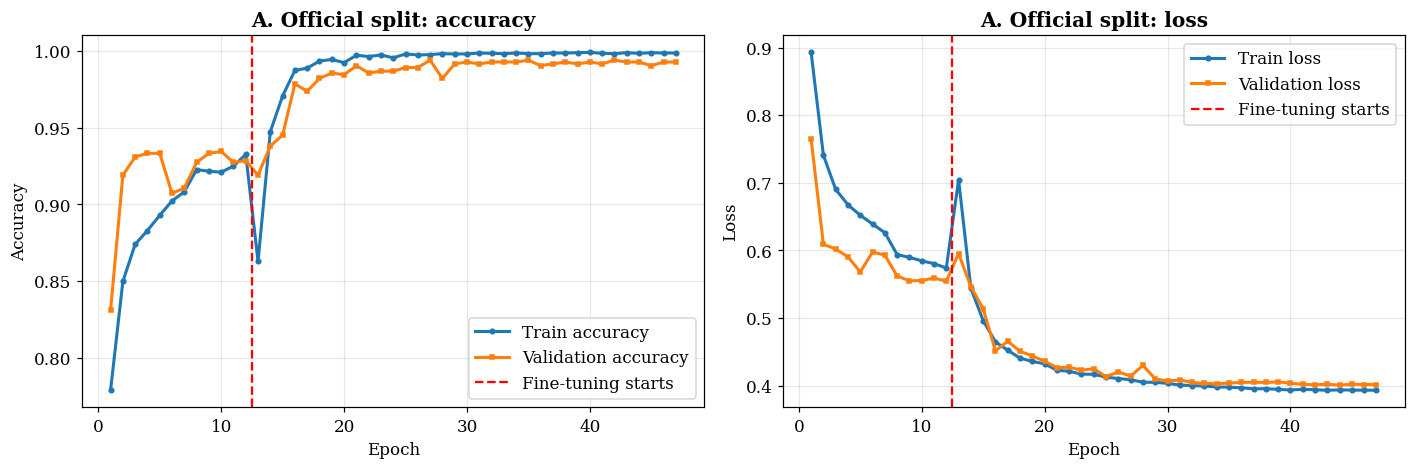

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_training_curves_protocol_A.png
   [A. Official split] test accuracy = 96.12% (73.0 min)

🚀 [B. Random image-level split] Phase 1 — classifier head
Epoch 1/12
158/158 - 131s - 829ms/step - accuracy: 0.7757 - loss: 0.9052 - val_accuracy: 0.8136 - val_loss: 0.7755 - learning_rate: 0.0010
Epoch 2/12
158/158 - 60s - 382ms/step - accuracy: 0.8448 - loss: 0.7398 - val_accuracy: 0.8923 - val_loss: 0.6498 - learning_rate: 0.0010
Epoch 3/12
158/158 - 59s - 371ms/step - accuracy: 0.8637 - loss: 0.7009 - val_accuracy: 0.8824 - val_loss: 0.6568 - learning_rate: 0.0010
Epoch 4/12
158/158 - 59s - 370ms/step - accuracy: 0.8799 - loss: 0.6788 - val_accuracy: 0.8594 - val_loss: 0.6921 - learning_rate: 0.0010
Epoch 5/12
158/158 - 59s - 374ms/step - accuracy: 0.8962 - loss: 0.6412 - val_accuracy: 0.9133 - val_loss: 0.6054 - learning_rate: 3.0000e-04
Epoch 6/12
158/158 - 59s - 372ms/step - accuracy: 0.9057 - loss: 0.6266 - val_accuracy: 0.8923 - val_l

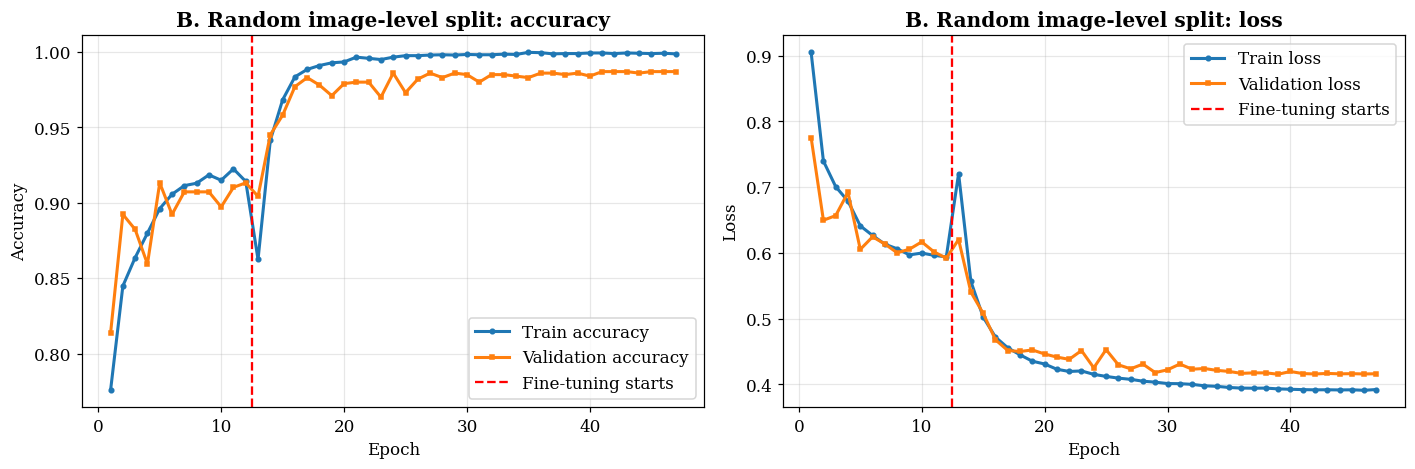

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_training_curves_protocol_B.png
   [B. Random image-level split] test accuracy = 98.64% (76.82 min)

🚀 [C. Group-aware split (ours)] Phase 1 — classifier head
Epoch 1/12
158/158 - 131s - 828ms/step - accuracy: 0.7665 - loss: 0.9218 - val_accuracy: 0.8495 - val_loss: 0.7155 - learning_rate: 0.0010
Epoch 2/12
158/158 - 63s - 397ms/step - accuracy: 0.8500 - loss: 0.7296 - val_accuracy: 0.8694 - val_loss: 0.6717 - learning_rate: 0.0010
Epoch 3/12
158/158 - 62s - 391ms/step - accuracy: 0.8633 - loss: 0.7068 - val_accuracy: 0.8335 - val_loss: 0.7346 - learning_rate: 0.0010
Epoch 4/12
158/158 - 63s - 397ms/step - accuracy: 0.8841 - loss: 0.6676 - val_accuracy: 0.8824 - val_loss: 0.6660 - learning_rate: 0.0010
Epoch 5/12
158/158 - 62s - 392ms/step - accuracy: 0.8868 - loss: 0.6578 - val_accuracy: 0.8824 - val_loss: 0.6459 - learning_rate: 0.0010
Epoch 6/12
158/158 - 62s - 392ms/step - accuracy: 0.8954 - loss: 0.6444 - val_accuracy: 0.8514 

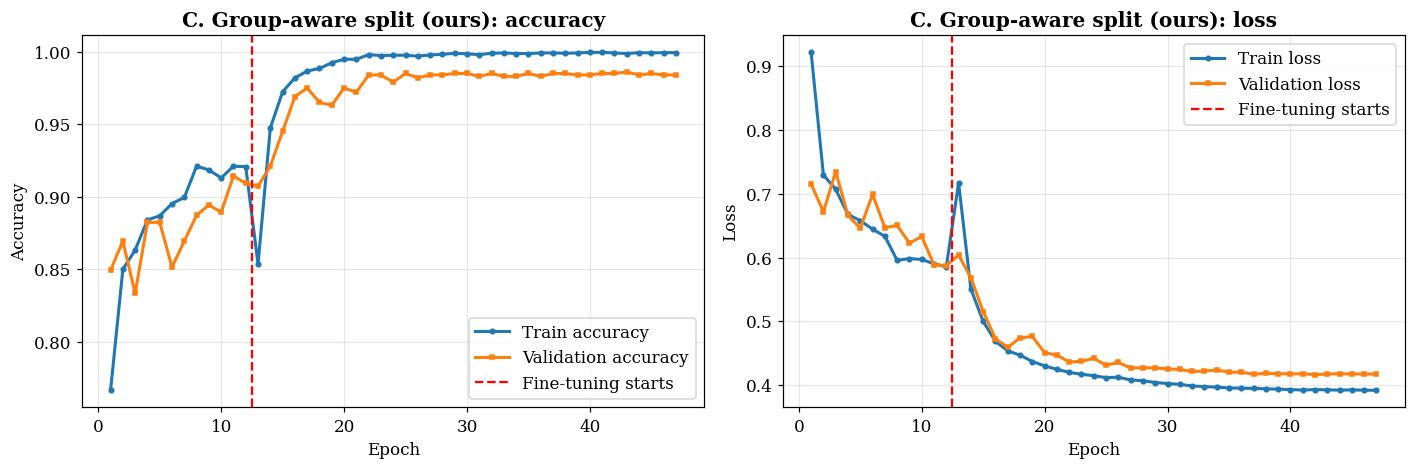

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_training_curves_protocol_C.png
   [C. Group-aware split (ours)] test accuracy = 97.69% (77.27 min)


In [12]:
# ============================================================
# CELL 8 — Train the same model under each protocol (≈ 35–45 min per protocol on a T4)
# ============================================================
CNN = {}
for k in SPLITS:
    probs, vprobs, hist, minutes = train_and_predict(k)
    CNN[k] = {"probs": probs, "val_probs": vprobs, "minutes": minutes}
    plot_history(hist, k)
    yt = label_ids(SPLITS[k][SPLITS[k].split == "test"])
    print(f"   [{PROTOCOLS[k]}] test accuracy = {100*accuracy_score(yt, probs.argmax(1)):.2f}% "
          f"({minutes} min)")
    np.save(os.path.join(TAB_DIR, f"test_probs_protocol_{k}.npy"), probs)

In [13]:
# ============================================================
# CELL 9 — Metrics: whole test set, and leaked vs unseen test images
# ============================================================
def bootstrap_ci(y, yp, fn, rounds=CFG["BOOTSTRAP_ROUNDS"], seed=SEED):
    if len(y) == 0:
        return (float("nan"), float("nan"))
    rng = np.random.default_rng(seed)
    vals = [fn(y[i], yp[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(rounds))]
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def full_metrics(y, probs):
    yp = probs.argmax(1)
    cm = confusion_matrix(y, yp, labels=range(len(CLASSES)))
    try:
        auc_m = roc_auc_score(np.eye(len(CLASSES))[y], probs, average="macro", multi_class="ovr")
    except ValueError:
        auc_m = float("nan")
    return {
        "accuracy": float(accuracy_score(y, yp)),
        "accuracy_95ci": bootstrap_ci(y, yp, accuracy_score),
        "balanced_accuracy": float(balanced_accuracy_score(y, yp)),
        "macro_f1": float(precision_recall_fscore_support(y, yp, average="macro", zero_division=0)[2]),
        "cohen_kappa": float(cohen_kappa_score(y, yp)), "mcc": float(matthews_corrcoef(y, yp)),
        "macro_roc_auc": float(auc_m),
        "log_loss": float(log_loss(y, np.clip(probs, 1e-7, 1), labels=range(len(CLASSES)))),
        "misclassified": int((yp != y).sum()),
        "tumours_predicted_as_no_tumour": int(sum(cm[c, CIDX["notumor"]] for c in range(4) if c != CIDX["notumor"])),
        "confusion_matrix": cm.tolist(),
    }


def subset_acc(y, yp, mask):
    if mask.sum() == 0:
        return {"n": 0, "accuracy": None, "accuracy_95ci": None}
    return {"n": int(mask.sum()), "accuracy": float(accuracy_score(y[mask], yp[mask])),
            "accuracy_95ci": bootstrap_ci(y[mask], yp[mask], accuracy_score)}


main_rows, sub_rows, RESULTS["protocols"] = [], [], {}
for k, d in SPLITS.items():
    te = d[d.split == "test"]
    y = label_ids(te)
    leaked = te["dup_in_dev"].to_numpy()
    cnn_m = full_metrics(y, CNN[k]["probs"])
    nn_pred = NN[k]["pred"]
    nn_acc = float(accuracy_score(y, nn_pred))
    res = {"name": PROTOCOLS[k], "model": MODEL_NAME, "test_images": int(len(y)),
           "val_accuracy": float(accuracy_score(label_ids(d[d.split == "val"]), CNN[k]["val_probs"].argmax(1))),
           "train_minutes": CNN[k]["minutes"], "cnn": cnn_m,
           "nn_memoriser": {"accuracy": nn_acc, "accuracy_95ci": bootstrap_ci(y, nn_pred, accuracy_score),
                            "median_nearest_similarity": float(np.median(NN[k]["sim"])),
                            "share_test_with_similarity_ge_0.90": float((NN[k]["sim"] >= 0.90).mean())},
           "subsets": {}}
    for name, mask in [("leaked", leaked), ("unseen", ~leaked)]:
        res["subsets"][name] = {"cnn": subset_acc(y, CNN[k]["probs"].argmax(1), mask),
                                "nn_memoriser": subset_acc(y, nn_pred, mask)}
        s = res["subsets"][name]
        sub_rows.append({"Protocol": PROTOCOLS[k], "Test subset": name, "Images": s["cnn"]["n"],
                         "CNN accuracy (%)": None if s["cnn"]["accuracy"] is None else round(100 * s["cnn"]["accuracy"], 2),
                         "1-NN accuracy (%)": None if s["nn_memoriser"]["accuracy"] is None else round(100 * s["nn_memoriser"]["accuracy"], 2)})
    RESULTS["protocols"][k] = res
    ci = cnn_m["accuracy_95ci"]
    main_rows.append({"Protocol": PROTOCOLS[k], "Test images": len(y),
                      "Leaked test (%)": round(100 * leaked.mean(), 2),
                      "CNN accuracy (%)": round(100 * cnn_m["accuracy"], 2),
                      "95% CI (%)": f"{100*ci[0]:.2f}–{100*ci[1]:.2f}",
                      "Macro-F1": round(cnn_m["macro_f1"], 4), "MCC": round(cnn_m["mcc"], 4),
                      "AUC": round(cnn_m["macro_roc_auc"], 4),
                      "Tumours missed": cnn_m["tumours_predicted_as_no_tumour"],
                      "1-NN memoriser accuracy (%)": round(100 * nn_acc, 2)})

MAIN = pd.DataFrame(main_rows)
SUB = pd.DataFrame(sub_rows)
MAIN.to_csv(os.path.join(TAB_DIR, "table_wp1_main.csv"), index=False)
SUB.to_csv(os.path.join(TAB_DIR, "table_wp1_leaked_vs_unseen.csv"), index=False)
pd.set_option("display.width", 250)
print(MAIN.to_string(index=False))
print("\n", SUB.to_string(index=False))

accC = RESULTS["protocols"]["C"]["cnn"]["accuracy"]
RESULTS["inflation_percentage_points"] = {
    k: round(100 * (RESULTS["protocols"][k]["cnn"]["accuracy"] - accC), 2) for k in ("A", "B")}
print("\nAccuracy inflation vs Protocol C (percentage points):", RESULTS["inflation_percentage_points"])
save_results()

                   Protocol  Test images  Leaked test (%)  CNN accuracy (%)  95% CI (%)  Macro-F1    MCC    AUC  Tumours missed  1-NN memoriser accuracy (%)
          A. Official split         1600            36.25             96.12 95.12–97.06    0.9608 0.9493 0.9928              17                        88.44
B. Random image-level split          954            34.07             98.64 97.80–99.27    0.9865 0.9819 0.9989               0                        91.51
C. Group-aware split (ours)          954             0.00             97.69 96.75–98.53    0.9769 0.9693 0.9985               1                        87.84

                    Protocol Test subset  Images  CNN accuracy (%)  1-NN accuracy (%)
          A. Official split      leaked     580             99.14              99.31
          A. Official split      unseen    1020             94.41              82.25
B. Random image-level split      leaked     325            100.00              99.69
B. Random image-level split   

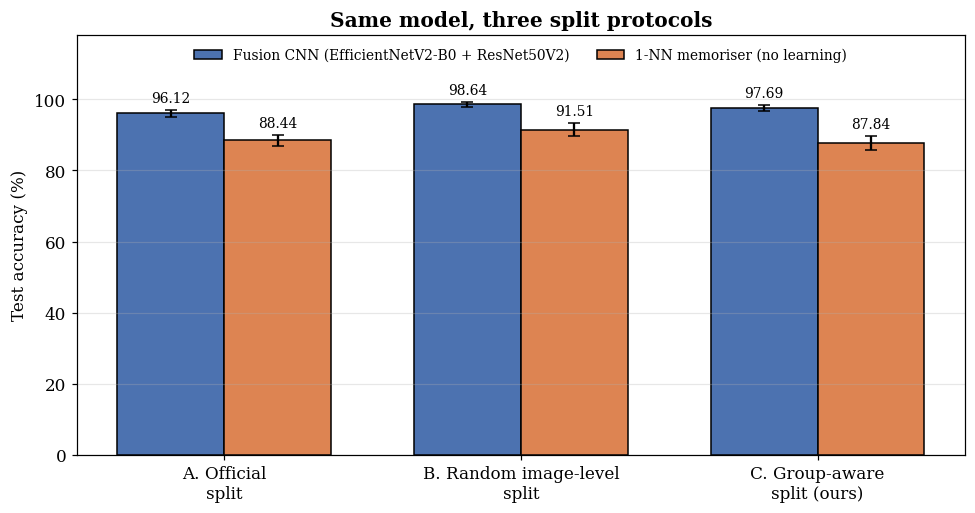

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_accuracy_by_protocol.png


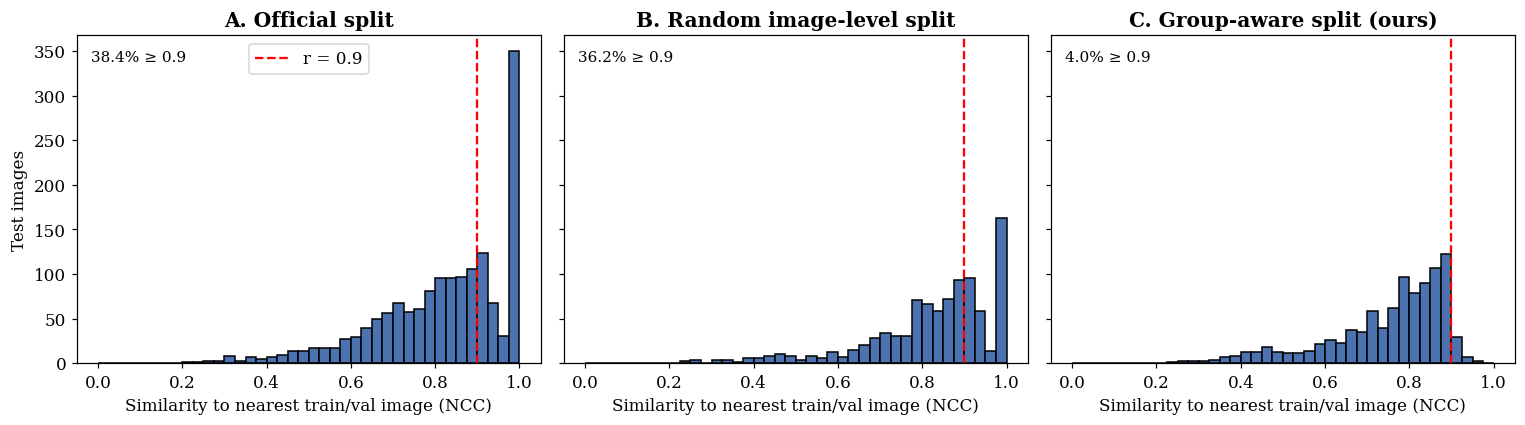

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_nearest_similarity.png


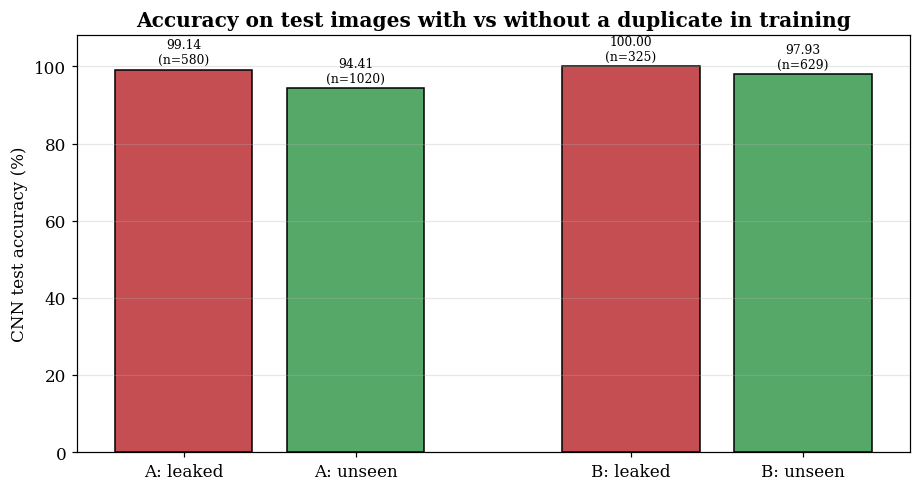

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_leaked_vs_unseen.png


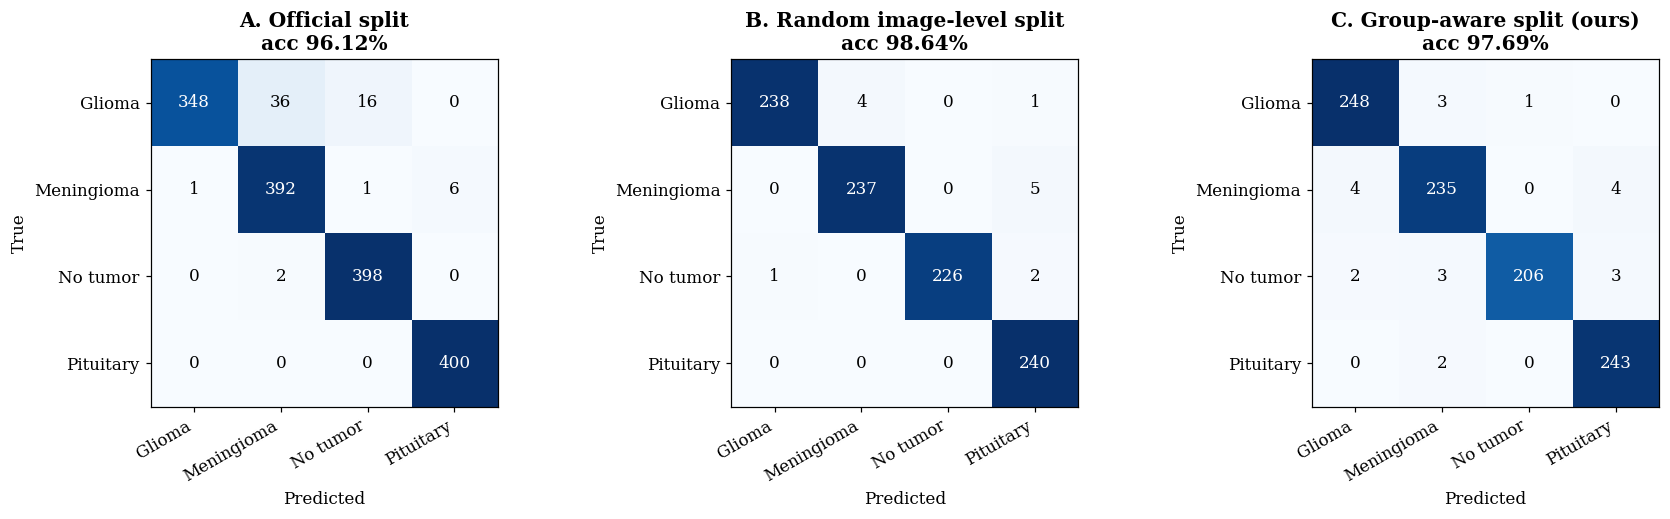

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_confusion_matrices.png


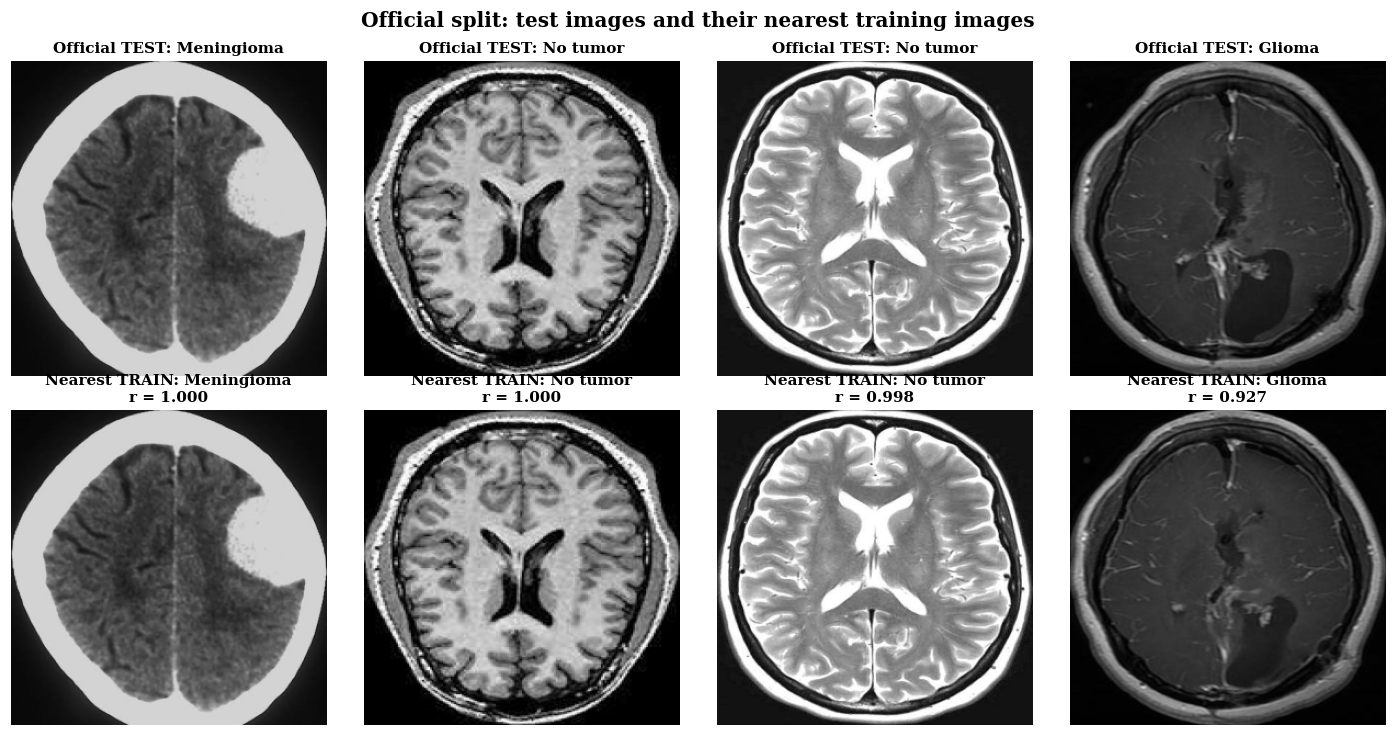

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_leak_examples.png


In [14]:
# ============================================================
# CELL 10 — Figures
# ============================================================
keys = list(SPLITS)
labels = [PROTOCOLS[k].replace(" split", "\nsplit") for k in keys]

# (1) accuracy by protocol, CNN vs memoriser, with 95% CI
fig, ax = plt.subplots(figsize=(9, 4.8))
w = 0.36
for j, (src, nm, col) in enumerate([("cnn", f"Fusion CNN ({MODEL_NAME})", "#4C72B0"),
                                    ("nn_memoriser", "1-NN memoriser (no learning)", "#DD8452")]):
    acc = np.array([RESULTS["protocols"][k][src]["accuracy"] for k in keys]) * 100
    ci = np.array([RESULTS["protocols"][k][src]["accuracy_95ci"] for k in keys]) * 100
    bars = ax.bar(np.arange(3) + (j - 0.5) * w, acc, w, yerr=[acc - ci[:, 0], ci[:, 1] - acc],
                  capsize=4, color=col, edgecolor="black", label=nm)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(np.arange(3)); ax.set_xticklabels(labels)
ax.set_ylabel("Test accuracy (%)"); ax.set_ylim(0, 118)
ax.set_title("Same model, three split protocols")
ax.legend(loc="upper center", ncol=2, fontsize=9, frameon=False); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_fig("fig_wp1_accuracy_by_protocol")

# (2) how similar is each test image to its nearest training image?
fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for a, k in zip(ax, keys):
    a.hist(NN[k]["sim"], bins=np.linspace(0, 1, 41), color="#4C72B0", edgecolor="black")
    a.axvline(CFG["NCC_MIN"], color="red", ls="--", lw=1.5, label=f"r = {CFG['NCC_MIN']}")
    a.set_title(PROTOCOLS[k]); a.set_xlabel("Similarity to nearest train/val image (NCC)")
    a.text(0.03, 0.92, f"{100*(NN[k]['sim'] >= CFG['NCC_MIN']).mean():.1f}% ≥ {CFG['NCC_MIN']}",
           transform=a.transAxes, fontsize=10)
ax[0].set_ylabel("Test images"); ax[0].legend(loc="upper center")
plt.tight_layout()
save_fig("fig_wp1_nearest_similarity")

# (3) leaked vs unseen test images
fig, ax = plt.subplots(figsize=(8.5, 4.6))
pos, ticks = 0, []
for k in ("A", "B"):
    for name, col in [("leaked", "#C44E52"), ("unseen", "#55A868")]:
        s = RESULTS["protocols"][k]["subsets"][name]["cnn"]
        if s["accuracy"] is not None:
            b = ax.bar(pos, 100 * s["accuracy"], 0.8, color=col, edgecolor="black")
            ax.bar_label(b, labels=[f"{100*s['accuracy']:.2f}\n(n={s['n']})"], fontsize=8, padding=2)
        ticks.append((pos, f"{k}: {name}"))
        pos += 1
    pos += 0.6
ax.set_xticks([p for p, _ in ticks]); ax.set_xticklabels([t for _, t in ticks])
ax.set_ylabel("CNN test accuracy (%)"); ax.set_ylim(0, 108)
ax.set_title("Accuracy on test images with vs without a duplicate in training"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_fig("fig_wp1_leaked_vs_unseen")

# (4) confusion matrices
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
names_c = [CLASS_TITLES[c] for c in CLASSES]
for a, k in zip(ax, keys):
    cm = np.array(RESULTS["protocols"][k]["cnn"]["confusion_matrix"])
    a.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4):
            a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks(range(4)); a.set_xticklabels(names_c, rotation=30, ha="right")
    a.set_yticks(range(4)); a.set_yticklabels(names_c)
    a.set_title(f"{PROTOCOLS[k]}\nacc {100*RESULTS['protocols'][k]['cnn']['accuracy']:.2f}%")
    a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout()
save_fig("fig_wp1_confusion_matrices")

# (5) examples: official test images next to their nearest training image
teA = dfA[dfA.split == "test"].reset_index(drop=True)
order = np.argsort(-NN["A"]["sim"])
pick = [order[int(q * (len(order) - 1))] for q in (0.0, 0.1, 0.2, 0.3)]
fig, ax = plt.subplots(2, 4, figsize=(13, 6.8))
for c, i in enumerate(pick):
    ax[0, c].imshow(cv2.cvtColor(cv2.imread(teA.loc[i, "path"]), cv2.COLOR_BGR2RGB))
    ax[0, c].set_title(f"Official TEST: {CLASS_TITLES[teA.loc[i, 'label']]}", fontsize=10)
    ax[1, c].imshow(cv2.cvtColor(cv2.imread(NN["A"]["nn_path"][i]), cv2.COLOR_BGR2RGB))
    ax[1, c].set_title(f"Nearest TRAIN: {CLASS_TITLES[CLASSES[NN['A']['nn_label'][i]]]}\nr = {NN['A']['sim'][i]:.3f}", fontsize=10)
    for a in ax[:, c]:
        a.axis("off")
plt.suptitle("Official split: test images and their nearest training images", fontweight="bold")
plt.tight_layout()
save_fig("fig_wp1_leak_examples")

In [18]:
# ============================================================
# CELL 11 — Summary + package outputs
# ============================================================
save_results()
print("=" * 88)
print(f"WP1 RESULT — {MODEL_NAME}, identical recipe, three split protocols")
print("=" * 88)
for k in keys:
    r = RESULTS["protocols"][k]
    print(f"{PROTOCOLS[k]:32s} | leaked test {100*SPLITS[k][SPLITS[k].split=='test'].dup_in_dev.mean():6.2f}% | "
          f"CNN {100*r['cnn']['accuracy']:6.2f}% | 1-NN memoriser {100*r['nn_memoriser']['accuracy']:6.2f}%")
print(f"Inflation vs C (pp): A {RESULTS['inflation_percentage_points']['A']:+.2f} | "
      f"B {RESULTS['inflation_percentage_points']['B']:+.2f}")
print("=" * 88)
zip_path = shutil.make_archive(os.path.join(CFG["WORK_DIR"], "wp1_outputs"), "zip", OUT_DIR)
print(f"\n📦 Saved: {zip_path} — download it from the Output panel.")

WP1 RESULT — EfficientNetV2-B0 + ResNet50V2, identical recipe, three split protocols
A. Official split                | leaked test  36.25% | CNN  96.12% | 1-NN memoriser  88.44%
B. Random image-level split      | leaked test  34.07% | CNN  98.64% | 1-NN memoriser  91.51%
C. Group-aware split (ours)      | leaked test   0.00% | CNN  97.69% | 1-NN memoriser  87.84%
Inflation vs C (pp): A -1.57 | B +0.94

📦 Saved: /kaggle/working/wp1_outputs.zip — download it from the Output panel.


CNN predictions available: False → running the 1-NN parts only (CNN files were deleted with the old session)
(a)+(b) Leaked vs unseen, controlling for class

                   Protocol Model  Leaked acc (%)  Unseen acc (%)  Unseen acc, leaked class mix (%)  Gap (pp)  Class-adjusted gap (pp) Fisher p CMH p (by class)
          A. Official split  1-NN           99.31           82.25                             91.33     17.06                     7.99 1.41e-32         7.08e-11
B. Random image-level split  1-NN           99.69           87.28                             88.52     12.41                    11.17 3.20e-14         1.81e-07

Per class:

Protocol Model      Class  Leaked n  Leaked acc (%)  Unseen n  Unseen acc (%)
       A  1-NN     Glioma        35           88.57       365           73.97
       A  1-NN Meningioma       148          100.00       252           81.35
       A  1-NN   No tumor       314          100.00        86           98.84
       A  1-NN  Pituitary        8

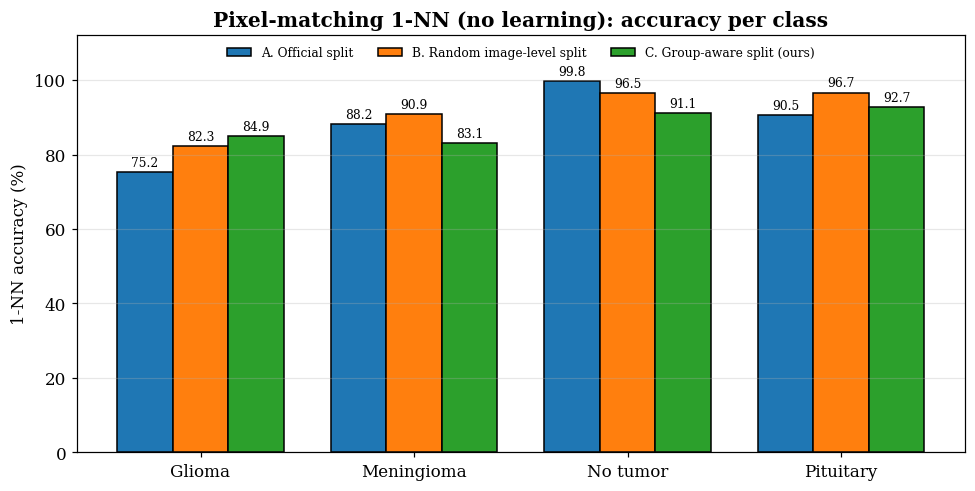

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_nn_per_class.png


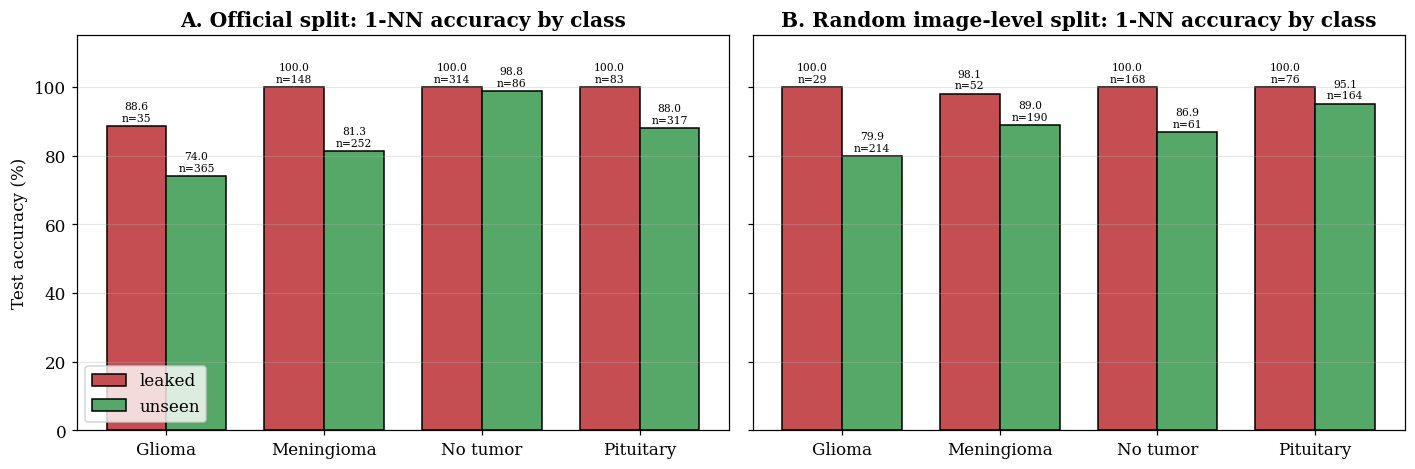

   saved -> /kaggle/working/wp1_outputs/figures/fig_wp1_leaked_vs_unseen_per_class.png

📦 Updated: /kaggle/working/wp1_outputs.zip


In [9]:
# ============================================================
# CELL 12 — Extra analysis (CPU, < 2 min): is the leakage effect real after controlling for class?
#   (a) leaked vs unseen accuracy per class + Cochran–Mantel–Haenszel test stratified by class
#   (b) unseen accuracy re-weighted to the class mix of the leaked images
#   (c) 1-NN memoriser accuracy per class (source-bias check)
#   (d) official-test glioma errors
# Works in two ways:
#   • same session, right after CELL 11; or
#   • after a restart: run CELLS 1–6 only (≈ 3 min, no training), then this cell.
#     CNN predictions are then loaded from wp1_outputs/tables/test_probs_protocol_*.npy if they still exist.
# ============================================================
if "CNN" not in globals() or not all(k in CNN for k in SPLITS):
    CNN = {}
    for k in SPLITS:
        f = os.path.join(TAB_DIR, f"test_probs_protocol_{k}.npy")
        if os.path.exists(f):
            CNN[k] = {"probs": np.load(f)}
HAVE_CNN = all(k in CNN for k in SPLITS)
print("CNN predictions available:", HAVE_CNN,
      "" if HAVE_CNN else "→ running the 1-NN parts only (CNN files were deleted with the old session)")
from scipy.stats import fisher_exact
try:
    from statsmodels.stats.contingency_tables import StratifiedTable
except Exception:
    StratifiedTable = None

EXTRA = {"leaked_vs_unseen": {}, "nn_per_class": {}, "official_glioma": {}}
per_class_rows, test_rows = [], []

for k in ("A", "B"):
    te = SPLITS[k][SPLITS[k].split == "test"]
    y, leaked = label_ids(te), te["dup_in_dev"].to_numpy()
    models = ([("CNN", CNN[k]["probs"].argmax(1))] if HAVE_CNN else []) + [("1-NN", NN[k]["pred"])]
    for model, pred in models:
        ok = pred == y
        tables, w, acc_u = [], [], []
        for c, cn in enumerate(CLASSES):
            m = y == c
            a, b = int((ok & leaked & m).sum()), int((~ok & leaked & m).sum())
            cc, d = int((ok & ~leaked & m).sum()), int((~ok & ~leaked & m).sum())
            per_class_rows.append({
                "Protocol": k, "Model": model, "Class": CLASS_TITLES[cn],
                "Leaked n": a + b, "Leaked acc (%)": round(100 * a / (a + b), 2) if a + b else None,
                "Unseen n": cc + d, "Unseen acc (%)": round(100 * cc / (cc + d), 2) if cc + d else None})
            if a + b and cc + d:
                tables.append(np.array([[a, b], [cc, d]], dtype=float))
                w.append(a + b); acc_u.append(cc / (cc + d))
        acc_l = ok[leaked].mean()
        acc_un = ok[~leaked].mean()
        acc_un_adj = float(np.average(acc_u, weights=w))          # unseen accuracy at the leaked class mix
        _, p_fisher = fisher_exact([[int((ok & leaked).sum()), int((~ok & leaked).sum())],
                                    [int((ok & ~leaked).sum()), int((~ok & ~leaked).sum())]])
        p_cmh = float("nan")
        if StratifiedTable is not None and tables:
            try:
                p_cmh = float(StratifiedTable(tables).test_null_odds(correction=True).pvalue)
            except Exception as e:
                print("CMH failed:", e)
        r = {"leaked_acc": float(acc_l), "unseen_acc": float(acc_un),
             "unseen_acc_at_leaked_class_mix": acc_un_adj,
             "gap_pp": round(100 * (acc_l - acc_un), 2),
             "gap_class_adjusted_pp": round(100 * (acc_l - acc_un_adj), 2),
             "fisher_p": float(p_fisher), "cmh_p_stratified_by_class": p_cmh}
        EXTRA["leaked_vs_unseen"][f"{k}_{model}"] = r
        test_rows.append({"Protocol": PROTOCOLS[k], "Model": model,
                          "Leaked acc (%)": round(100 * acc_l, 2), "Unseen acc (%)": round(100 * acc_un, 2),
                          "Unseen acc, leaked class mix (%)": round(100 * acc_un_adj, 2),
                          "Gap (pp)": r["gap_pp"], "Class-adjusted gap (pp)": r["gap_class_adjusted_pp"],
                          "Fisher p": f"{p_fisher:.2e}", "CMH p (by class)": f"{p_cmh:.2e}"})

PER_CLASS = pd.DataFrame(per_class_rows)
LEAK_TESTS = pd.DataFrame(test_rows)
PER_CLASS.to_csv(os.path.join(TAB_DIR, "table_wp1_leaked_vs_unseen_per_class.csv"), index=False)
LEAK_TESTS.to_csv(os.path.join(TAB_DIR, "table_wp1_leaked_vs_unseen_tests.csv"), index=False)
print("(a)+(b) Leaked vs unseen, controlling for class\n")
print(LEAK_TESTS.to_string(index=False))
print("\nPer class:\n")
print(PER_CLASS.to_string(index=False))

# ---- (c) 1-NN memoriser accuracy per class ----
nn_rows = []
for k in SPLITS:
    te = SPLITS[k][SPLITS[k].split == "test"]
    y = label_ids(te)
    row = {"Protocol": PROTOCOLS[k]}
    for c, cn in enumerate(CLASSES):
        m = y == c
        row[CLASS_TITLES[cn]] = round(100 * (NN[k]["pred"][m] == c).mean(), 2)
        EXTRA["nn_per_class"].setdefault(k, {})[cn] = row[CLASS_TITLES[cn]]
    row["Overall"] = round(100 * (NN[k]["pred"] == y).mean(), 2)
    nn_rows.append(row)
NN_CLASS = pd.DataFrame(nn_rows)
NN_CLASS.to_csv(os.path.join(TAB_DIR, "table_wp1_nn_per_class.csv"), index=False)
print("\n(c) 1-NN memoriser accuracy per class (%)\n")
print(NN_CLASS.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.6))
wd = 0.26
for j, k in enumerate(SPLITS):
    vals = [NN_CLASS.iloc[j][CLASS_TITLES[c]] for c in CLASSES]
    b = ax.bar(np.arange(4) + (j - 1) * wd, vals, wd, label=PROTOCOLS[k], edgecolor="black")
    ax.bar_label(b, fmt="%.1f", fontsize=8, padding=2)
ax.set_xticks(np.arange(4)); ax.set_xticklabels([CLASS_TITLES[c] for c in CLASSES])
ax.set_ylabel("1-NN accuracy (%)"); ax.set_ylim(0, 112)
ax.set_title("Pixel-matching 1-NN (no learning): accuracy per class")
ax.legend(loc="upper center", ncol=3, fontsize=8, frameon=False); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_fig("fig_wp1_nn_per_class")

# ---- class-stratified leaked vs unseen figure ----
FIG_MODEL = "CNN" if HAVE_CNN else "1-NN"
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for a, k in zip(ax, ("A", "B")):
    sub = PER_CLASS[(PER_CLASS.Protocol == k) & (PER_CLASS.Model == FIG_MODEL)]
    x = np.arange(len(sub))
    for j, (col, nm, colr) in enumerate([("Leaked acc (%)", "leaked", "#C44E52"),
                                          ("Unseen acc (%)", "unseen", "#55A868")]):
        v = sub[col].astype(float).fillna(0).to_numpy()
        n = sub["Leaked n" if nm == "leaked" else "Unseen n"].to_numpy()
        b = a.bar(x + (j - 0.5) * 0.38, v, 0.38, color=colr, edgecolor="black", label=nm)
        a.bar_label(b, labels=[f"{vv:.1f}\nn={nn}" if nn else "–" for vv, nn in zip(v, n)], fontsize=7, padding=2)
    a.set_xticks(x); a.set_xticklabels(sub["Class"]); a.set_ylim(0, 115)
    a.set_title(f"{PROTOCOLS[k]}: {FIG_MODEL} accuracy by class"); a.grid(axis="y", alpha=0.3)
ax[0].set_ylabel("Test accuracy (%)"); ax[0].legend(loc="lower left")
plt.tight_layout()
save_fig("fig_wp1_leaked_vs_unseen_per_class")

# ---- (d) official-test glioma errors (CNN only) ----
if HAVE_CNN:
    teA = SPLITS["A"][SPLITS["A"].split == "test"].reset_index(drop=True)
    yA, pA = label_ids(teA), CNN["A"]["probs"].argmax(1)
    g = CIDX["glioma"]
    gm = yA == g
    wrong_g = np.where(gm & (pA != g))[0]
    simA = NN["A"]["sim"]
    EXTRA["official_glioma"] = {
        "test_gliomas": int(gm.sum()), "wrong": int(len(wrong_g)),
        "predicted_as": {CLASS_TITLES[CLASSES[c]]: int((pA[wrong_g] == c).sum()) for c in range(4) if c != g},
        "wrong_that_are_leaked": int(teA.loc[wrong_g, "dup_in_dev"].sum()),
        "median_nearest_sim_wrong": float(np.median(simA[wrong_g])) if len(wrong_g) else None,
        "median_nearest_sim_correct": float(np.median(simA[gm & (pA == g)])),
    }
    print("\n(d) Official-test gliomas:", json.dumps(EXTRA["official_glioma"], indent=2))

    if len(wrong_g):
        show = wrong_g[np.argsort(simA[wrong_g])][:8]
        cols = min(4, len(show)); rws = int(np.ceil(len(show) / cols))
        fig, ax = plt.subplots(rws, cols, figsize=(3.4 * cols, 3.9 * rws))
        ax = np.array(ax).reshape(-1)
        for a in ax:
            a.axis("off")
        for a, i in zip(ax, show):
            a.imshow(cv2.cvtColor(cv2.imread(teA.loc[i, "path"]), cv2.COLOR_BGR2RGB))
            a.set_title(f"Glioma → {CLASS_TITLES[CLASSES[pA[i]]]}\nnearest-train r = {simA[i]:.2f}", fontsize=9, color="red")
        plt.suptitle("Official test: misclassified gliomas (least similar to training first)", fontweight="bold")
        plt.tight_layout()
        save_fig("fig_wp1_official_glioma_errors")


if "RESULTS" not in globals():
    RESULTS = {}
RESULTS["extra_analysis"] = EXTRA
save_results()
zip_path = shutil.make_archive(os.path.join(CFG["WORK_DIR"], "wp1_outputs"), "zip", OUT_DIR)
print(f"\n📦 Updated: {zip_path}")